# Who Should We Post a Flu Jab To?
## Seasonal flu vaccine allocation for a town, Dataset A (Group A)

| | |
|---|---|
| **Hackathon** | Data Science Challenge, Wednesday 11 November 2026 |
| **GitHub organisation** | `https://github.com/Team-A-Hackathon/Team-A-Hackathon`  |
| **Colab notebook** | `https://colab.research.google.com/drive/1FPoUmV_ka-ZpsWyyQes5umhVdogiIrPe?usp=sharing`  |
| **Target** | `seasonal_vaccine` (1 = the person takes the seasonal flu vaccine) |
| **What we submit** | for each test resident: 1 = post a vaccine, 0 = do not |

**Team A**

| Member | Student ID | Role | Notebook sections owned |
|---|---|---|---|
| Sindhu Gaddam | 24071473 | Team lead and integrator: runs the shared Colab, merges work, writes and checks the 5 submission files, submits on Canvas | setup (A.1), F.1 |
| Vamshi Bureboina | 24085801 | Metric researcher: works out the town-cost metric and the decision rule, collects the generative-AI hospitalisation estimates | A.2-A.4 |
| Nishanth Baddam | 24073866 | Data analyst (EDA 1): data quality, target, missing values, key features | B.1-B.6 |
| Likhitha Jonnala | 24077942 | Data analyst (EDA 2): remaining features, association ranking, missing patterns, train/test check, EDA decisions | B.7-B.12 |
| Trinath Chandra Bose Bolla | 24073534 | Modeller 1: pre-processing pipelines, logistic regression, neural network, pre-processing comparison | C.1-C.3 |
| Vinay Konda | 24079973 | Modeller 2: tree models, hyper-parameter tuning, calibration, stacking | C.4-C.6 |
| Chandrika | 24098812 | Evaluator, model comparsion, decision rules,robustness,critical review | D, E |
|Venkata Ravi Kumar Nidamanuri |24064958 |XAI lead and communication lead:explainability for all models(SHAP, permutation importance,coefficients) and the non-expert summary slide | F.2, F-4 |


**Contents**

* **Part A, the problem:** what the town pays for, and how a single prediction turns into dollars
* **Part B, the data:** data-quality audit, every feature against uptake, association ranking, missing-data patterns, an interaction, a train/test shift check, and the decisions the exploration led to
* **Part C, the models:** pre-processing options compared, then nine candidate models (five families, three tuned, one calibrated, one stacked), all judged by the town's bill under the same 10-fold cross-validation, repeated twice
* **Part D, the decision:** how the cut-off is set, and how much it matters
* **Part E, robustness:** do the conclusions survive different hospitalisation assumptions?
* **Part F, delivery:** the five ranked submission files, explainability, and an honest review

## Part A. The problem
### A.1 Setup

In [3]:
import importlib.util, subprocess, sys
for pkg in ["lightgbm", "shap"]:            # both ship with Colab; install only if missing
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from lightgbm import LGBMClassifier

RANDOM_STATE = 2026
GROUP_ID = "A"          # CHECK: use the group letter/number the lecturers gave us for the file names
TARGET, KEY = "seasonal_vaccine", "respondent_id"

PALETTE = {"take": "#1b9e77", "refuse": "#d95f02", "neutral": "#7570b3", "grey": "#9e9e9e"}
sns.set_theme(style="ticks", palette="colorblind", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [4]:
# Colab: point DATA_DIR at the raw GitHub folder, e.g. "https://raw.githubusercontent.com/<ORG>/<REPO>/main/data/"
DATA_DIR = ""
df_train = pd.read_csv(DATA_DIR + "dataset_A_training.csv")
df_test = pd.read_csv(DATA_DIR + "dataset_A_testing.csv")
df_example = pd.read_csv(DATA_DIR + "dataset_A_example_submission.csv")

y = df_train[TARGET].to_numpy()
print(f"training rows {len(df_train):,} | test rows {len(df_test):,} | features {df_test.shape[1] - 1}")
print("example submission:", list(df_example.columns), "| dtype of target:", df_example[TARGET].dtype)
assert df_example[KEY].equals(df_test[KEY]), "example ids should follow the test file order"

training rows 4,756 | test rows 4,749 | features 29
example submission: ['respondent_id', 'seasonal_vaccine'] | dtype of target: float64


### A.2 What the town pays for
From the dataset sheet and the target metric sheet:

* everybody catches the flu (100% infection, winter indoor parties);
* a vaccine posted to a home costs **$300**, and is wasted if the person does not want it;
* anyone who **wants** a vaccine but is not sent one must be paid **$300 in cash** (they stay unvaccinated);
* a flu hospitalisation costs **$18,500**; the chance of one depends on the person and on whether they were vaccinated.

So for each resident there are four possible outcomes:

| | resident would take it | resident would refuse it |
|---|---|---|
| **we post a vaccine** | $300 + vaccinated risk × $18,500 | $300 wasted + unvaccinated risk × $18,500 |
| **we do not post one** | $300 cash + unvaccinated risk × $18,500 | unvaccinated risk × $18,500 |

The $300 is paid in three of the four cells. The only cell where posting changes the hospital bill is the top-left one.

### A.3 Turning a probability into a decision
Let `q` be the model's probability that a resident takes the vaccine, `r_u` and `r_v` their hospitalisation risk without and with the vaccine, `V = 300` and `H = 18,500`.

Posting a vaccine instead of not posting one:

* **expected extra spend** = `(1 − q) · V` (the dose is wasted when they refuse; when they accept we would have paid the cash anyway);
* **expected saving** = `q · (r_u − r_v) · H` (a hospital stay avoided, only if they accept).

Post the vaccine when the saving is larger than the extra spend:

$$q \cdot (r_u - r_v)\,H \;>\; (1-q)\,V \quad\Longleftrightarrow\quad q \;>\; \frac{V}{V + (r_u - r_v)\,H}$$

The cut-off is **different for every resident**. Frail, older residents are worth a dose even when we are unsure they will use it; for a healthy 25-year-old the dose has to be almost certain to be used.

### A.4 Hospitalisation risk (generative-AI research)
The sheet asks us to estimate hospitalisation probabilities with generative AI, asking more than one AI or more than one person. Three models were each asked the same question separately (prompt below), without seeing each other's answers or any suggested values, and the code uses the plain average of their answers.

> *Everyone in a town is infected with seasonal flu (H3N2). For adults aged 18-34, 35-44, 45-54, 55-64 and 65+ with no chronic condition, what is P(hospitalised | infected, unvaccinated), per infection, not per symptomatic case? What fraction of hospitalisations does the vaccine prevent? By what factor does each chronic condition multiply the risk (compounding)?*

| Asked | 18-34 | 35-44 | 45-54 | 55-64 | 65+ | vaccine cuts risk by | each chronic condition multiplies risk by |
|---|---|---|---|---|---|---|---|
| Claude Sonnet | 0.0015 | 0.002 | 0.004 | 0.007 | 0.022 | 40% | 2.0 |
| Claude Haiku | 0.0002 | 0.0005 | 0.001 | 0.003 | 0.008 | 40% | 2.0 |
| Claude Fable | 0.0012 | 0.0018 | 0.0028 | 0.0045 | 0.025 | 35% | 2.0 |
| **Average (used)** | **0.0010** | **0.0014** | **0.0026** | **0.0048** | **0.0183** | **38.3%** | **2.0** |

What the answers had in common: all three started from CDC seasonal-flu burden estimates (hospitalisations per symptomatic illness), scaled them down to *per infection* because many infections are mild or silent, and scaled down again for people with no chronic condition. They agree closely on the vaccine effect (35-40%, lower in H3N2 seasons) and the chronic multiplier (2.0). They disagree most on the absolute risk for younger adults (up to about 7 times), and all three said those values could be out by a factor of 2-3. That disagreement is why Part E re-scores everything from 0.4 to 2 times these risks.

*If team members ask other AIs (e.g. Gemini, ChatGPT), add a row and update the average.*

In [5]:
COST_VACCINE = 300.0          # given on the Dataset A sheet
COST_HOSPITAL = 18_500.0      # given on the Dataset A sheet

# ---- assumptions: averaged generative-AI answers (table in A.4) ----
RISK_TABLE = pd.DataFrame({
    "age_group": ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"],
    "risk_unvaccinated": [0.00097, 0.00143, 0.0026, 0.00483, 0.01833],   # mean of the three AI answers in A.4
}).set_index("age_group")["risk_unvaccinated"]
VACCINE_EFFECT = 0.383        # share of hospitalisations prevented by the jab (mean of 0.40, 0.40, 0.35)
CHRONIC_FACTOR = 2.0          # risk multiplier for each chronic condition, compounding (all three AIs said 2.0)


def resident_risk(frame, table=RISK_TABLE, effect=VACCINE_EFFECT, chronic_factor=CHRONIC_FACTOR):
    # hospitalisation probability of each resident without (r_u) and with (r_v) the vaccine
    base = frame["age_group"].map(table).fillna(table.mean()).to_numpy(float)
    n_chronic = frame["number_chronic_med_conditions"].fillna(0).to_numpy(float)
    r_u = np.minimum(base * chronic_factor ** n_chronic, 1.0)
    return r_u, r_u * (1 - effect)


def town_bill(takes, posted, r_u, r_v, V=COST_VACCINE, H=COST_HOSPITAL):
    # total dollars the town spends; lower is better
    takes = np.asarray(takes, dtype=bool)
    posted = np.asarray(posted, dtype=bool)
    vaccines = V * (posted | takes)                     # posted dose, or cash for a resident who wanted one
    protected = posted & takes                          # only a posted AND accepted dose lowers risk
    hospital = H * np.where(protected, r_v, r_u)
    return float((vaccines + hospital).sum())


def cutoff(r_u, r_v, V=COST_VACCINE, H=COST_HOSPITAL):
    return V / (V + (r_u - r_v) * H)


def post_vaccine(q, r_u, r_v, V=COST_VACCINE, H=COST_HOSPITAL):
    return np.asarray(q) > cutoff(r_u, r_v, V, H)

In [6]:
# Sanity check by hand: four 65+ residents with one chronic condition, one in each cell of the A.2 table
check = pd.DataFrame({"age_group": ["65+ Years"] * 4, "number_chronic_med_conditions": [1] * 4})
ru, rv = resident_risk(check)
takes, posted = [1, 0, 1, 0], [1, 1, 0, 0]
by_hand = (300 + rv[0] * 18_500) + (300 + ru[0] * 18_500) + (300 + ru[0] * 18_500) + ru[0] * 18_500
assert np.isclose(town_bill(takes, posted, ru, rv), by_hand)
print(f"r_u = {ru[0]:.3f}, r_v = {rv[0]:.4f}, bill for the four = ${by_hand:,.2f} (matches)")
print(f"this resident is worth a dose when P(take) > {cutoff(ru, rv)[0]:.2f}")

r_u = 0.037, r_v = 0.0226, bill for the four = $3,353.09 (matches)
this resident is worth a dose when P(take) > 0.54


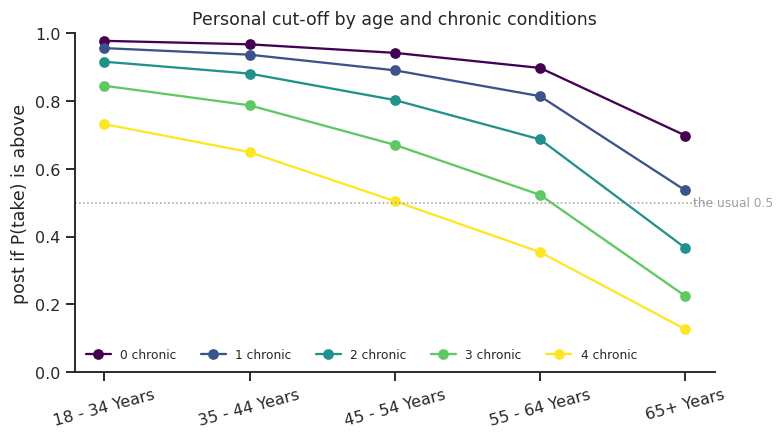

In [7]:
grid = pd.MultiIndex.from_product([RISK_TABLE.index, range(5)], names=["age_group", "number_chronic_med_conditions"]).to_frame(index=False)
grid["cutoff"] = cutoff(*resident_risk(grid))
fig, ax = plt.subplots(figsize=(7.5, 4))
for k, (n, part) in enumerate(grid.groupby("number_chronic_med_conditions")):
    ax.plot(part["age_group"], part["cutoff"], marker="o", label=f"{n} chronic", color=plt.cm.viridis(k / 4))
ax.axhline(0.5, color=PALETTE["grey"], ls=":", lw=1)
ax.text(4.05, 0.5, "the usual 0.5", va="center", fontsize=8, color=PALETTE["grey"])
ax.set(ylim=(0, 1), ylabel="post if P(take) is above", title="Personal cut-off by age and chronic conditions")
ax.legend(frameon=False, ncol=5, loc="lower left", fontsize=8); plt.xticks(rotation=15); plt.show()

In [8]:
r_u_train, r_v_train = resident_risk(df_train)
r_u_test, r_v_test = resident_risk(df_test)
N = len(df_train)

reference = {
    "post to nobody": np.zeros(N, bool),
    "post to everybody": np.ones(N, bool),
    "post to the 65+ only": (df_train["age_group"] == "65+ Years").to_numpy(),
    "oracle (knows who takes it)": y.astype(bool),
}
reference = pd.Series({k: town_bill(y, p, r_u_train, r_v_train) / N for k, p in reference.items()},
                      name="$ per resident").to_frame()
reference.style.format("${:,.2f}")

,$ per resident
post to nobody,$360.42
post to everybody,$446.10
post to the 65+ only,$338.91
oracle (knows who takes it),$307.01


Any model must beat all three simple rules, and nothing can beat the oracle. The gap between "post to nobody" and the oracle is the most money a perfect model could save.

## Part B. The data

### B.1 Data quality
Before any plots: check every column against the dataset sheet (type, allowed values, missing share in both files), and make sure ids are unique and the test set does not overlap the training set.

In [9]:
BINARY = [c for c in df_train if c.startswith("behavioral_")] + ["doctor_recc_seasonal", "child_under_6_months",
                                                                  "health_worker", "health_insurance"]
SHEET_RANGE = {"flu_concern": (0, 3), "flu_knowledge": (0, 2), "opinion_seas_vacc_effective": (1, 5),
               "opinion_seas_risk": (1, 5), "opinion_seas_sick_from_vacc": (1, 5), "household_adults": (0, 3),
               "household_children": (0, 3), "number_chronic_med_conditions": (0, 8), **{c: (0, 1) for c in BINARY}}

rows = []
for col in df_test.columns.drop(KEY):
    both = pd.concat([df_train[col], df_test[col]])
    numeric = pd.api.types.is_numeric_dtype(both)
    lo, hi = SHEET_RANGE.get(col, (None, None))
    rows.append({"column": col, "type": "numeric" if numeric else "text", "levels": both.nunique(),
                 "% missing train": round(df_train[col].isna().mean() * 100, 1),
                 "% missing test": round(df_test[col].isna().mean() * 100, 1),
                 "min": both.min() if numeric else "", "max": both.max() if numeric else "",
                 "sheet range": f"{lo}-{hi}" if lo is not None else "categories",
                 "within sheet range": bool(both.dropna().between(lo, hi).all()) if lo is not None else True})
audit = pd.DataFrame(rows).set_index("column")

assert audit["within sheet range"].all(), audit[~audit["within sheet range"]]
assert not df_train[KEY].duplicated().any() and not df_test[KEY].duplicated().any()
assert not set(df_train[KEY]) & set(df_test[KEY]), "a respondent appears in both files"
assert set(df_train[TARGET].unique()) == {0, 1}
print(f"all values within the ranges on the dataset sheet | duplicate ids: 0 | train/test overlap: 0 | "
      f"fully duplicated training rows: {df_train.drop(columns=KEY).duplicated().sum()}")
audit

all values within the ranges on the dataset sheet | duplicate ids: 0 | train/test overlap: 0 | fully duplicated training rows: 0


,type,levels,% missing train,% missing test,min,max,sheet range,within sheet range
column,,,,,,,,
flu_concern,numeric,4,0.3,0.4,0.0,3.0,0-3,True
flu_knowledge,numeric,3,0.5,0.4,0.0,2.0,0-2,True
behavioral_antiviral_meds,numeric,2,0.3,0.3,0.0,1.0,0-1,True
behavioral_avoidance,numeric,2,0.7,1.0,0.0,1.0,0-1,True
behavioral_face_mask,numeric,2,0.1,0.1,0.0,1.0,0-1,True
behavioral_wash_hands,numeric,2,0.2,0.1,0.0,1.0,0-1,True
behavioral_large_gatherings,numeric,2,0.2,0.6,0.0,1.0,0-1,True
behavioral_outside_home,numeric,2,0.2,0.3,0.0,1.0,0-1,True
behavioral_touch_face,numeric,2,0.4,0.6,0.0,1.0,0-1,True


### B.2 Target and missing values

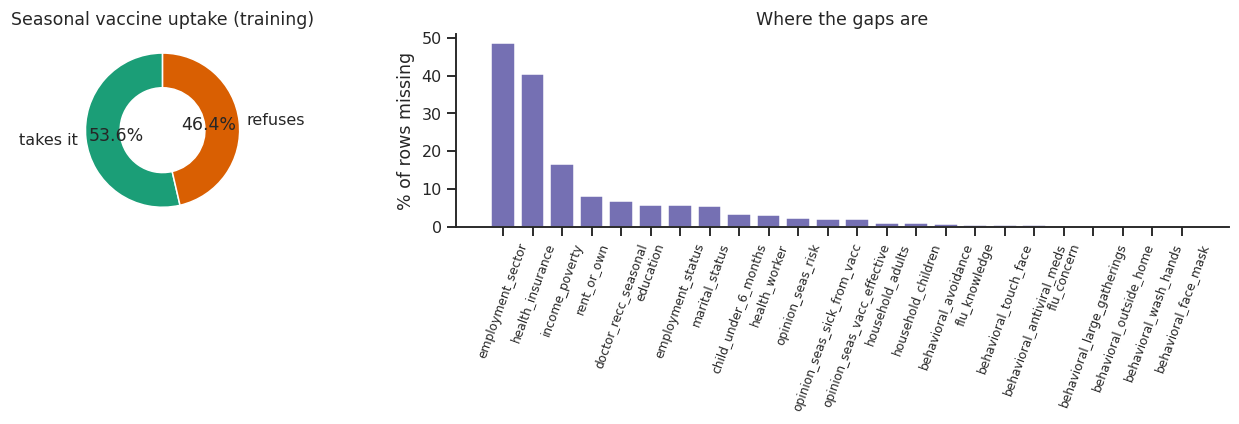

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2.2]})
counts = pd.Series(y).map({1: "takes it", 0: "refuses"}).value_counts()
axes[0].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
            colors=[PALETTE["take"], PALETTE["refuse"]], wedgeprops={"width": 0.45})
axes[0].set_title("Seasonal vaccine uptake (training)")

missing = df_train.isna().mean().mul(100).loc[lambda s: s > 0].sort_values(ascending=False)
axes[1].bar(missing.index, missing.values, color=PALETTE["neutral"])
axes[1].set(ylabel="% of rows missing", title="Where the gaps are")
axes[1].tick_params(axis="x", rotation=70, labelsize=8)
plt.tight_layout(); plt.show()

The classes are close to balanced (about 54% take the jab), so the difficulty is not imbalance but deciding **who** to post to. `employment_sector` (about half missing) and `health_insurance` (about 40% missing) are the big gaps. The next cell shows that a missing sector almost always means the person is not employed, so the gaps are kept as information instead of being filled with a guess.

In [11]:
# Is a missing employment_sector random, or does it mean something?
sector_gap = pd.crosstab(df_train["employment_status"].fillna("missing"), df_train["employment_sector"].isna(),
                         margins=True).rename(columns={False: "sector given", True: "sector missing"})
print(sector_gap)
print(f"\nmissing sector belongs to someone not employed (or status missing) in "
      f"{1 - sector_gap.loc['Employed', 'sector missing'] / sector_gap.loc['All', 'sector missing']:.1%} of cases")
print("uptake when insurance is missing:", round(df_train.loc[df_train['health_insurance'].isna(), TARGET].mean(), 3),
      "| insured:", round(df_train.loc[df_train['health_insurance'] == 1, TARGET].mean(), 3),
      "| uninsured:", round(df_train.loc[df_train['health_insurance'] == 0, TARGET].mean(), 3))

employment_sector   sector given  sector missing   All
employment_status                                     
Employed                    2442              25  2467
Not in Labor Force             0            1786  1786
Unemployed                     0             234   234
missing                        0             269   269
All                         2442            2314  4756

missing sector belongs to someone not employed (or status missing) in 98.9% of cases
uptake when insurance is missing: 0.462 | insured: 0.628 | uninsured: 0.258


### B.3 Protective behaviours

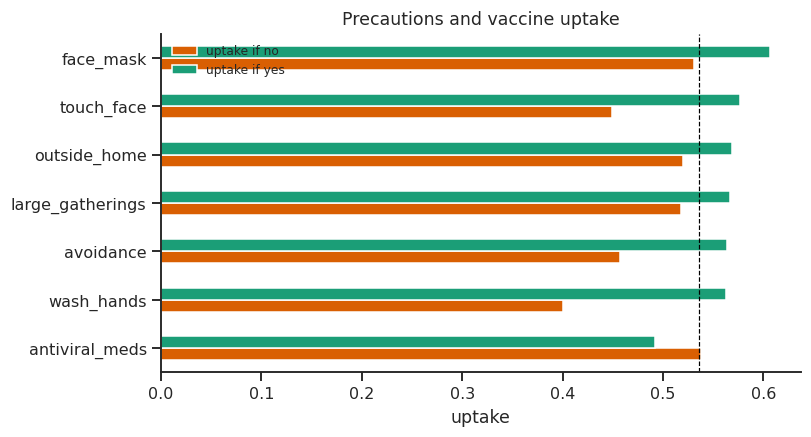

,share who do it,uptake if yes,uptake if no
antiviral_meds,0.052,0.492,0.538
avoidance,0.734,0.564,0.457
face_mask,0.074,0.607,0.531
wash_hands,0.837,0.563,0.401
large_gatherings,0.365,0.567,0.518
outside_home,0.337,0.569,0.520
touch_face,0.688,0.577,0.449


In [12]:
# The seven protective behaviours: how common is each, and does it go with uptake?
beh = pd.DataFrame({"share who do it": df_train[[c for c in df_train if c.startswith('behavioral_')]].mean(),
                    "uptake if yes": [df_train.loc[df_train[c] == 1, TARGET].mean() for c in df_train if c.startswith('behavioral_')],
                    "uptake if no": [df_train.loc[df_train[c] == 0, TARGET].mean() for c in df_train if c.startswith('behavioral_')]})
beh.index = beh.index.str.replace("behavioral_", "")
ax = beh[["uptake if no", "uptake if yes"]].sort_values("uptake if yes").plot(kind="barh", figsize=(7.5, 4),
                                                                            color=[PALETTE["refuse"], PALETTE["take"]])
ax.axvline(y.mean(), color="black", lw=0.8, ls="--"); ax.set_xlabel("uptake"); ax.set_title("Precautions and vaccine uptake")
ax.legend(frameon=False, fontsize=8); plt.show()
beh.round(3)

### B.4 Uptake by the key features

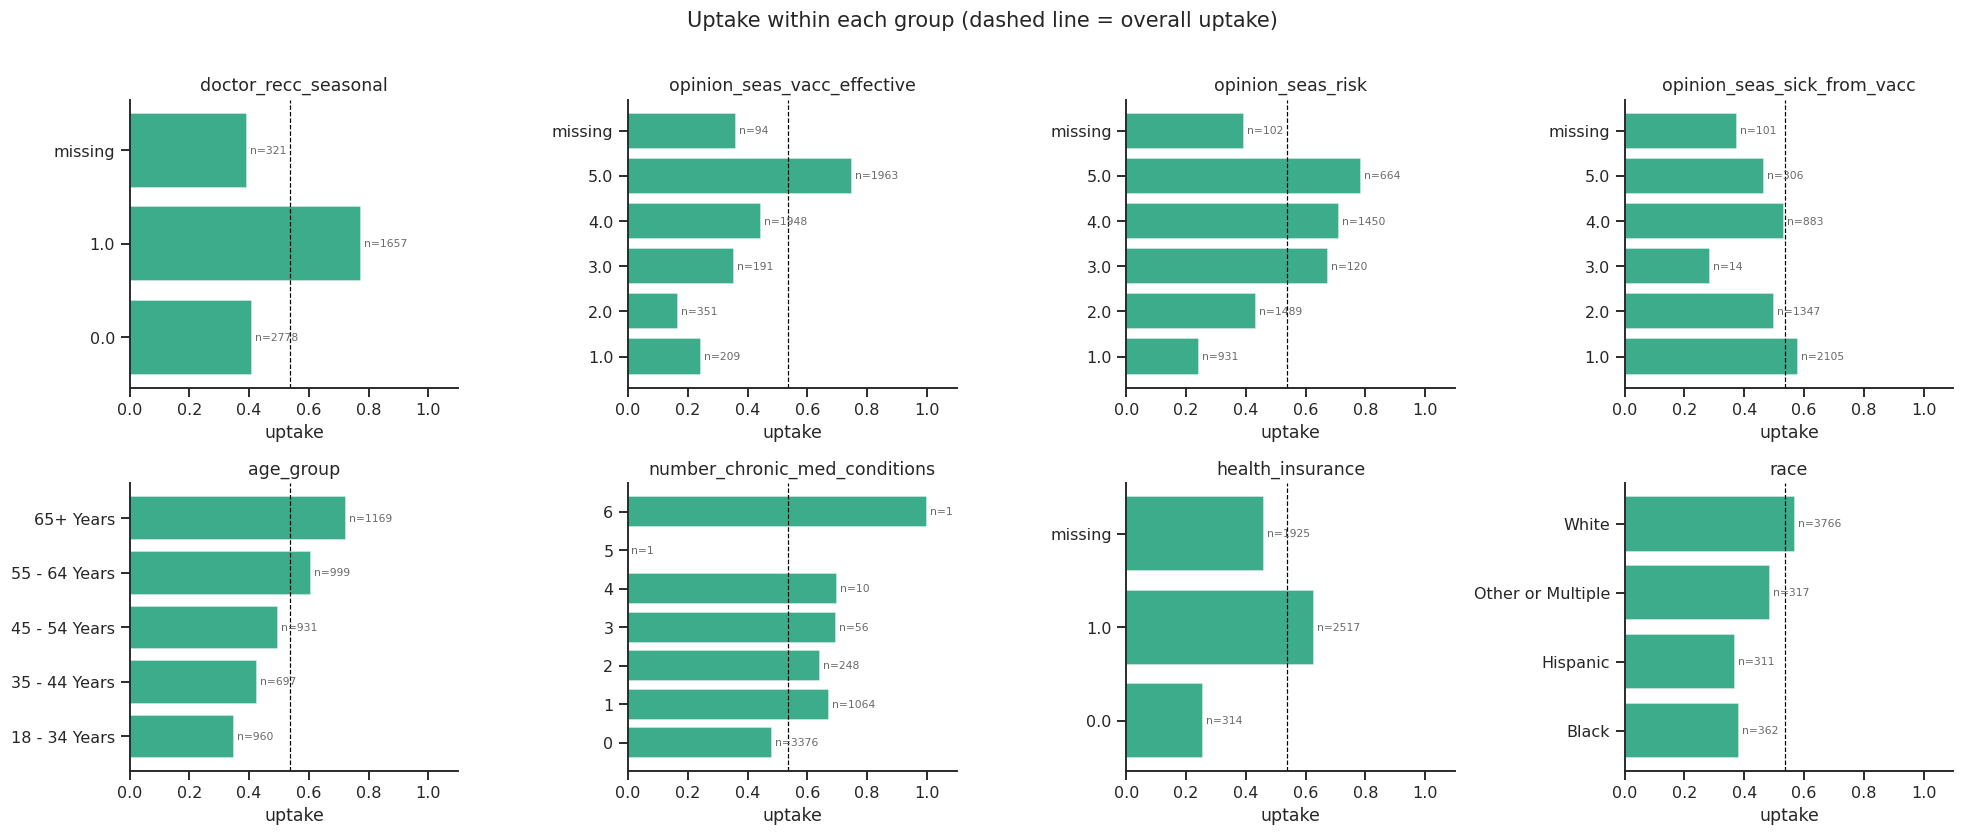

In [13]:
def uptake_by(col, ax, order=None):
    s = df_train[col].astype("string").fillna("missing")
    tab = df_train.groupby(s)[TARGET].agg(rate="mean", n="size")
    if order is not None:
        tab = tab.reindex([o for o in order if o in tab.index])
    ax.barh(tab.index, tab["rate"], color=PALETTE["take"], alpha=0.85)
    ax.axvline(y.mean(), color="black", lw=0.8, ls="--")
    for i, (rate, n) in enumerate(zip(tab["rate"], tab["n"])):
        ax.text(rate + 0.01, i, f"n={n}", va="center", fontsize=7, color="dimgrey")
    ax.set(xlim=(0, 1.1), title=col, xlabel="uptake")

panels = ["doctor_recc_seasonal", "opinion_seas_vacc_effective", "opinion_seas_risk", "opinion_seas_sick_from_vacc",
          "age_group", "number_chronic_med_conditions", "health_insurance", "race"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, col in zip(axes.ravel(), panels):
    uptake_by(col, ax)
fig.suptitle("Uptake within each group (dashed line = overall uptake)", y=1.01); plt.tight_layout(); plt.show()

A doctor's recommendation, the respondent's own opinions about the vaccine and age separate takers from refusers most clearly. Age and chronic conditions matter in a second way: they also set the hospitalisation risk, so they move both `q` and the personal cut-off.

Note the opinion scales: 3 means "Don't know", which sits in the middle of the numbers but is not a middle opinion. Treating these columns as plain numbers assumes an order that may not hold; section C.3 tests the alternative.

### B.5 Correlation between the ordinal answers

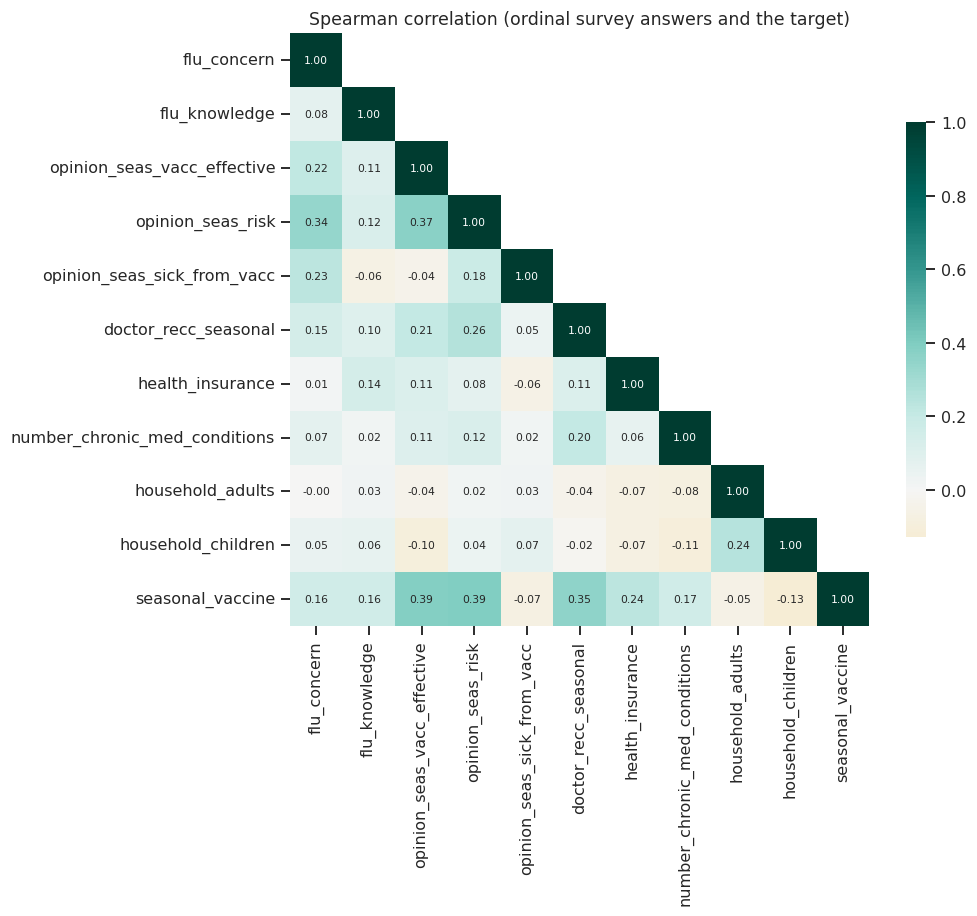

In [14]:
ordinal = ["flu_concern", "flu_knowledge", "opinion_seas_vacc_effective", "opinion_seas_risk", "opinion_seas_sick_from_vacc",
           "doctor_recc_seasonal", "health_insurance", "number_chronic_med_conditions", "household_adults", "household_children"]
rho = df_train[ordinal + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(rho, dtype=bool), k=1)
plt.figure(figsize=(8.5, 7))
sns.heatmap(rho, mask=mask, cmap="BrBG", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.title("Spearman correlation (ordinal survey answers and the target)"); plt.show()

### B.6 Where the hospital risk sits

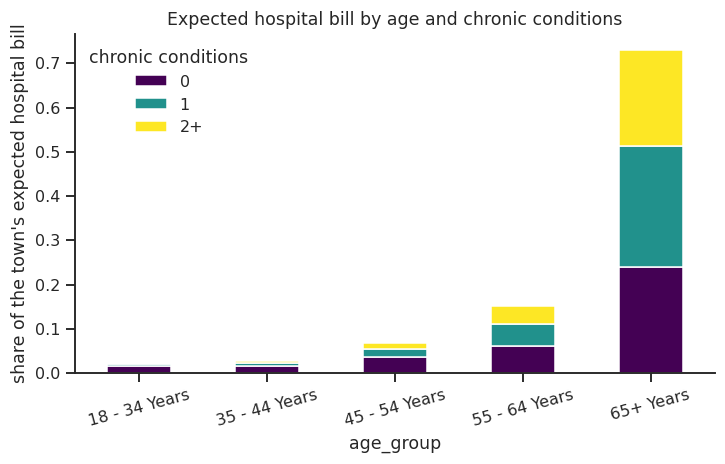

65+ residents are 24.6% of the town but carry 73.0% of the expected hospital bill (with the A.4 assumptions).


In [15]:
# Where does the money sit? Expected hospital bill per resident if nobody were vaccinated
exp_bill = pd.DataFrame({"age_group": df_train["age_group"], "bill": r_u_train * COST_HOSPITAL,
                         "chronic": df_train["number_chronic_med_conditions"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})})
share = exp_bill.groupby(["age_group", "chronic"])["bill"].sum().unstack() / exp_bill["bill"].sum()
share.plot(kind="bar", stacked=True, figsize=(7.5, 4), colormap="viridis", rot=15)
plt.ylabel("share of the town's expected hospital bill"); plt.title("Expected hospital bill by age and chronic conditions")
plt.legend(title="chronic conditions", frameon=False); plt.show()
is_old = (df_train["age_group"] == "65+ Years").to_numpy()
print(f"65+ residents are {is_old.mean():.1%} of the town but carry {exp_bill['bill'][is_old].sum() / exp_bill['bill'].sum():.1%} "
      f"of the expected hospital bill (with the A.4 assumptions).")

### B.7 The remaining features
Uptake for every feature not shown above, so that no column goes unexamined.

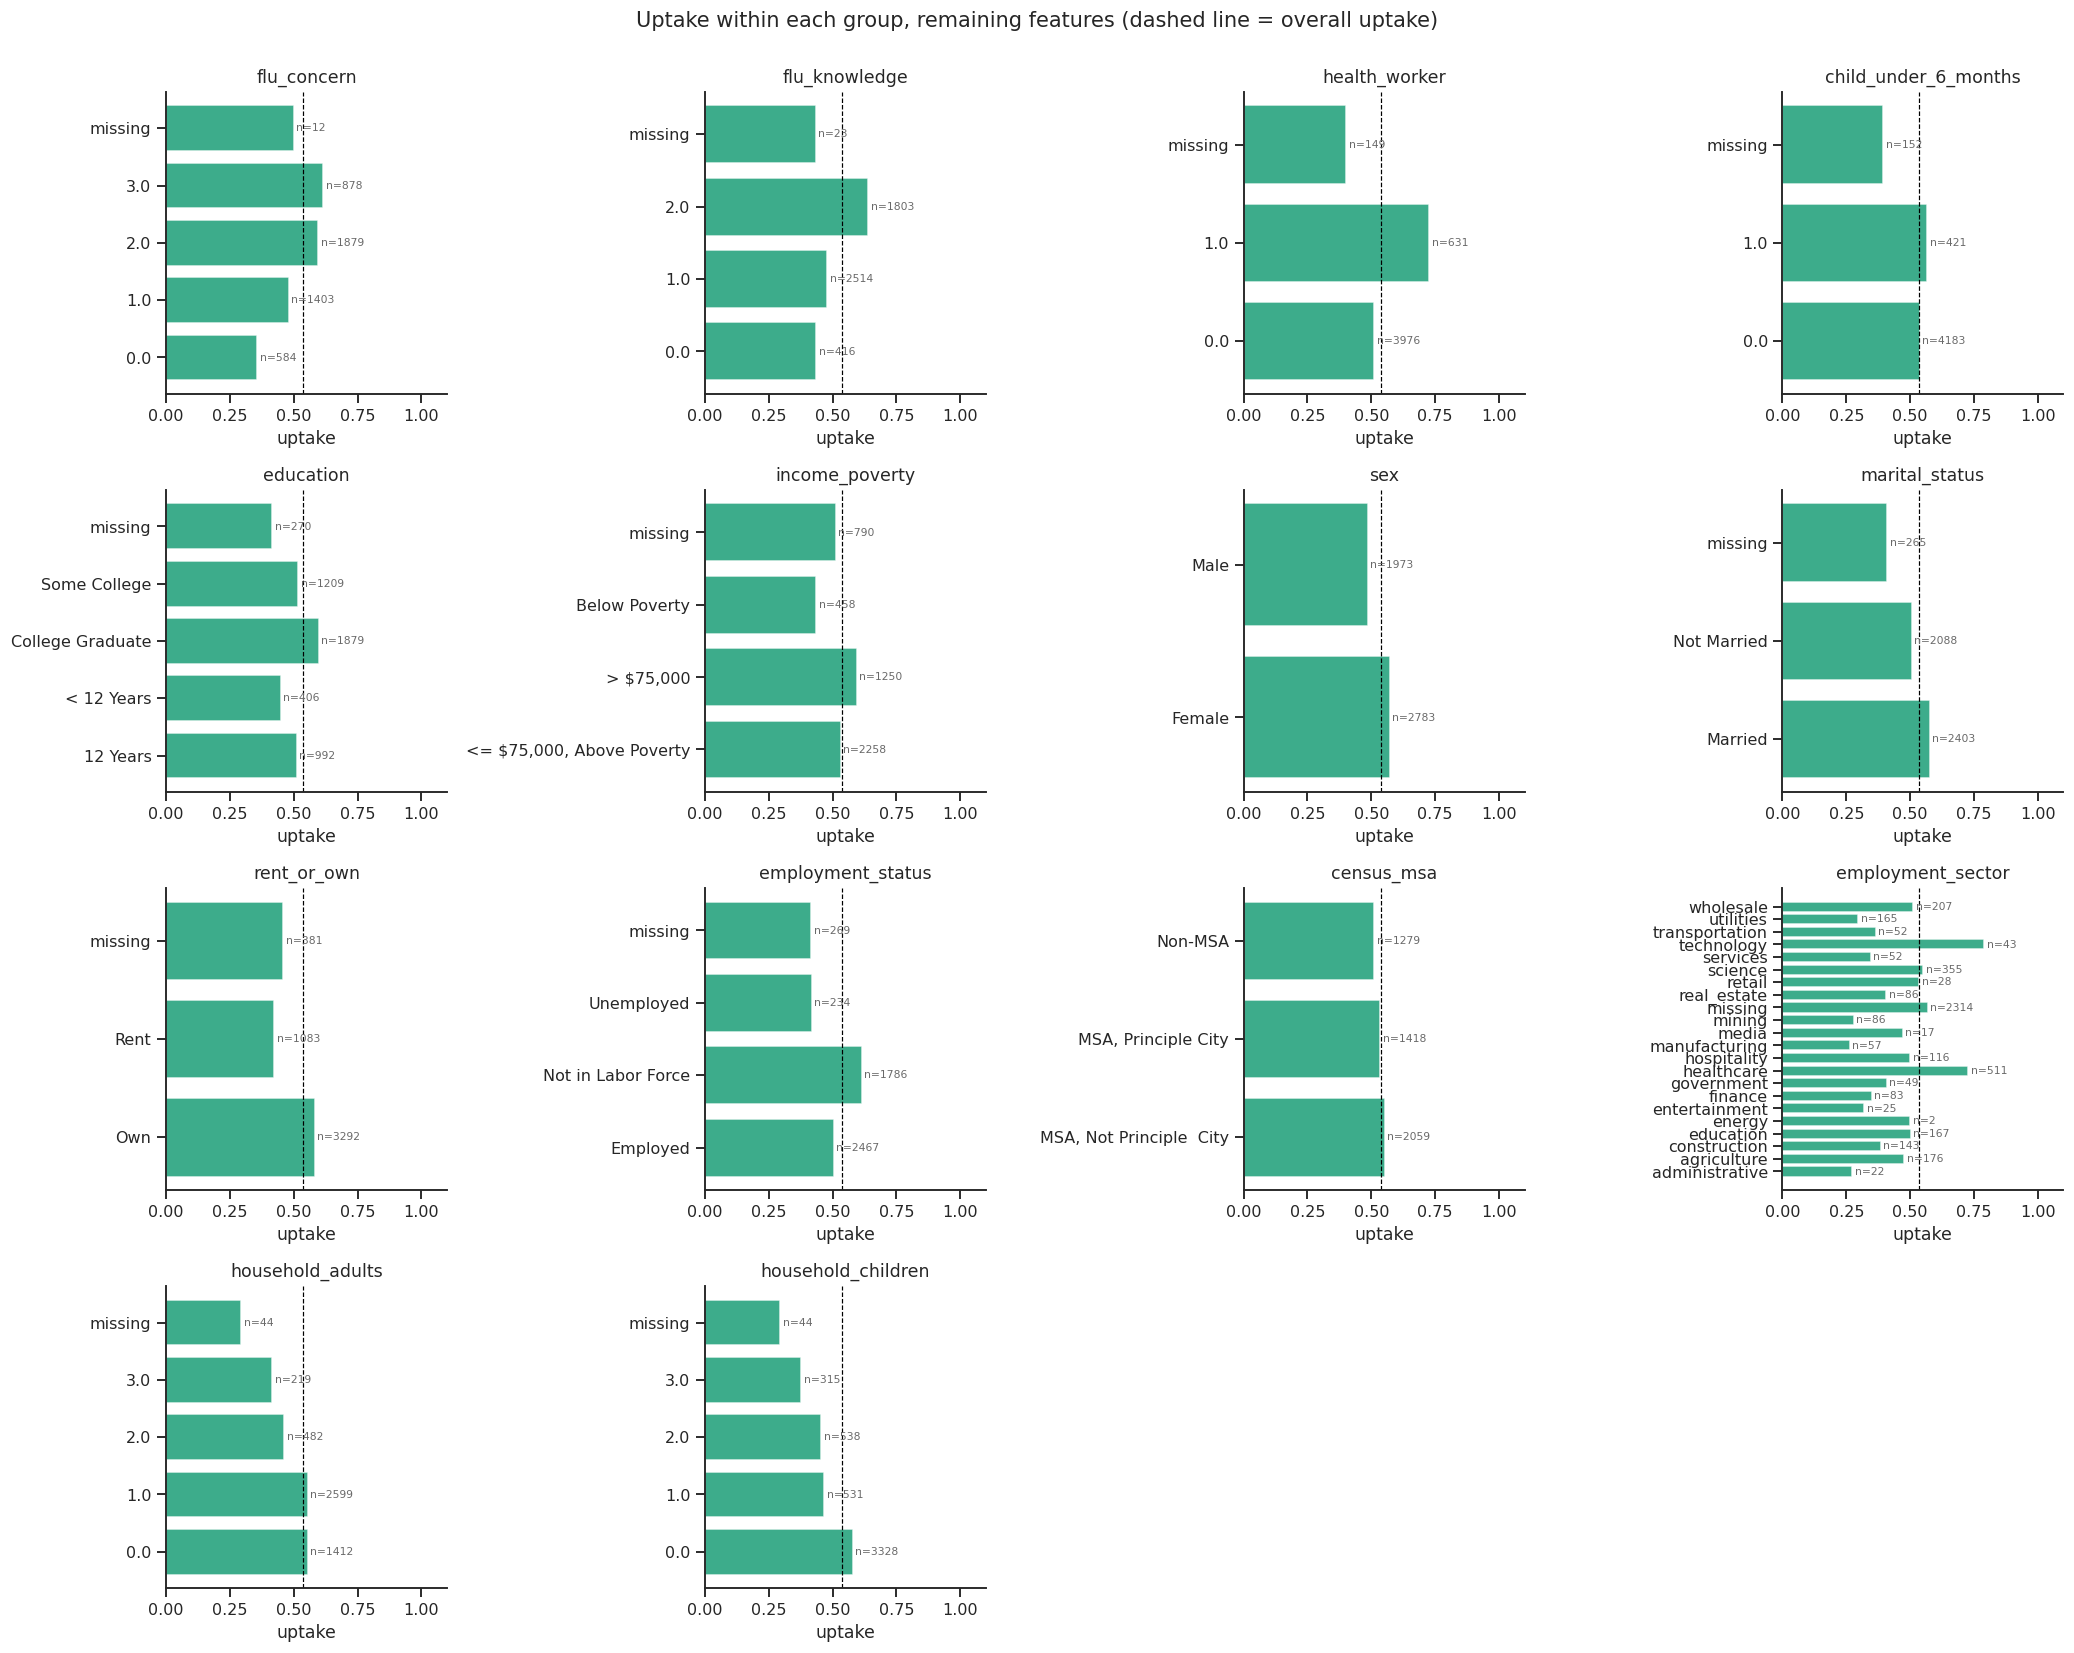

In [16]:
rest = ["flu_concern", "flu_knowledge", "health_worker", "child_under_6_months", "education", "income_poverty",
        "sex", "marital_status", "rent_or_own", "employment_status", "census_msa", "employment_sector",
        "household_adults", "household_children"]
fig, axes = plt.subplots(4, 4, figsize=(19, 15))
for ax, col in zip(axes.ravel(), rest):
    uptake_by(col, ax)
for ax in axes.ravel()[len(rest):]:
    ax.axis("off")
fig.suptitle("Uptake within each group, remaining features (dashed line = overall uptake)", y=1.0); plt.tight_layout(); plt.show()

### B.8 Which features are most related to uptake?
One number per feature so that all 29 can be compared: **Cramér's V** between the feature (each value, including "missing", treated as a category) and the target. 0 means no relation, 1 a perfect one. It works the same for text, ordinal and binary columns, and it catches non-linear patterns that a correlation would miss.

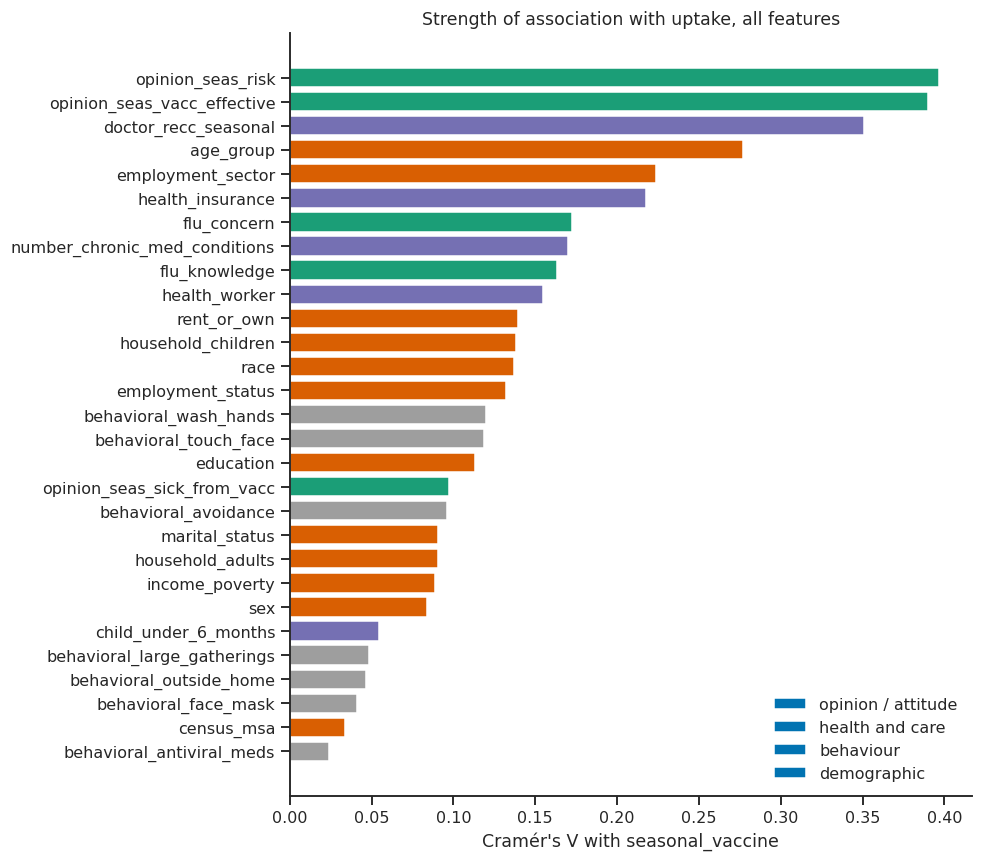

strongest five: opinion_seas_risk (0.40), opinion_seas_vacc_effective (0.39), doctor_recc_seasonal (0.35), age_group (0.28), employment_sector (0.22)
weakest five:   behavioral_antiviral_meds (0.02), census_msa (0.03), behavioral_face_mask (0.04), behavioral_outside_home (0.05), behavioral_large_gatherings (0.05)


In [17]:
from scipy.stats import chi2_contingency


def cramers_v(feature, target):
    table = pd.crosstab(feature.astype("string").fillna("missing"), target)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


GROUPS = {"opinion / attitude": ["flu_concern", "flu_knowledge"] + [c for c in df_train if c.startswith("opinion_")],
          "health and care": ["doctor_recc_seasonal", "health_insurance", "health_worker", "child_under_6_months",
                              "number_chronic_med_conditions"],
          "behaviour": [c for c in df_train if c.startswith("behavioral_")]}
group_of = {c: g for g, cols in GROUPS.items() for c in cols}
assoc = pd.DataFrame({"cramers_v": {c: cramers_v(df_train[c], df_train[TARGET]) for c in df_test.columns.drop(KEY)}})
assoc["group"] = [group_of.get(c, "demographic") for c in assoc.index]
assoc = assoc.sort_values("cramers_v")

colours = {"opinion / attitude": PALETTE["take"], "health and care": PALETTE["neutral"],
           "behaviour": PALETTE["grey"], "demographic": PALETTE["refuse"]}
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(assoc.index, assoc["cramers_v"], color=assoc["group"].map(colours))
for g, c in colours.items():
    ax.barh([], [], color=c, label=g)
ax.set(xlabel="Cramér's V with seasonal_vaccine", title="Strength of association with uptake, all features")
ax.legend(frameon=False, loc="lower right"); plt.show()
print("strongest five:", ", ".join(f"{c} ({v:.2f})" for c, v in assoc["cramers_v"].sort_values(ascending=False).head(5).items()))
print("weakest five:  ", ", ".join(f"{c} ({v:.2f})" for c, v in assoc["cramers_v"].sort_values().head(5).items()))

### B.9 Do the gaps come together?
If the same people skip many questions, missingness is a property of the respondent, not of a single question, and it may itself predict uptake.

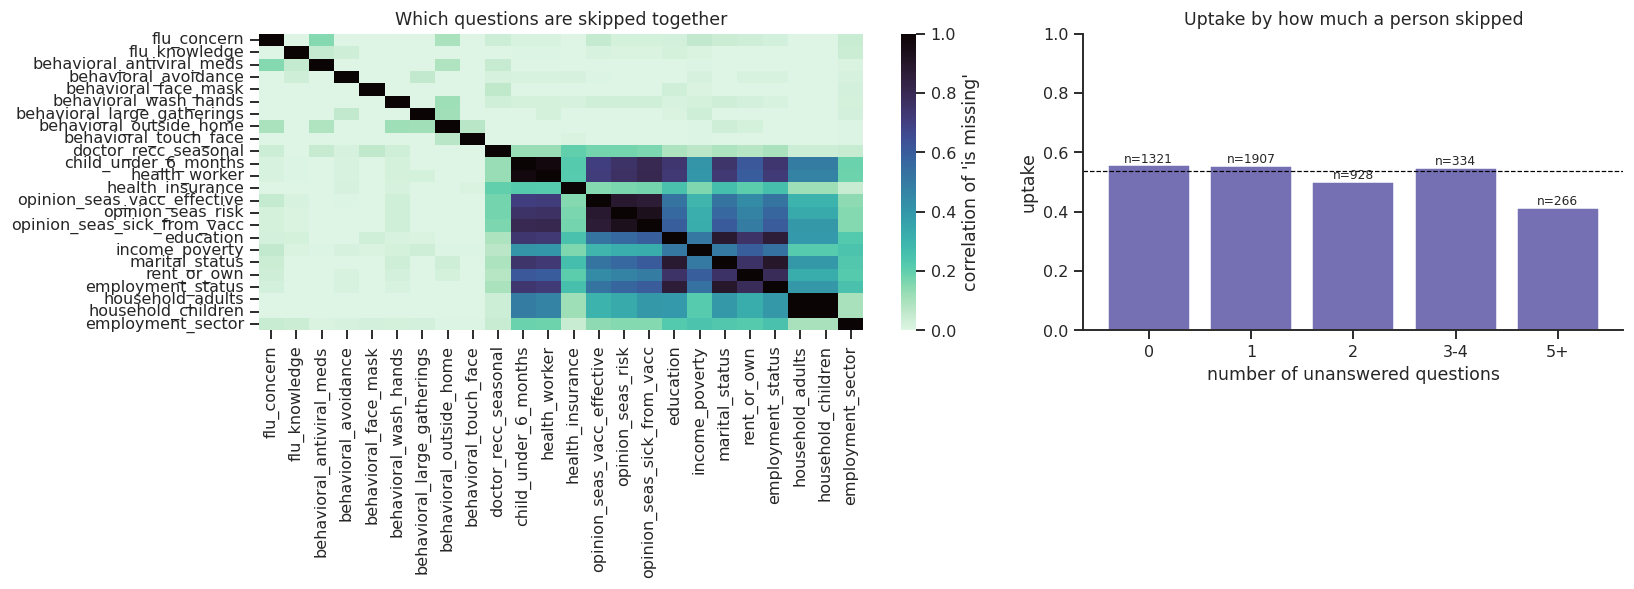

      mean  size
0    0.557  1321
1    0.554  1907
2    0.501   928
3-4  0.548   334
5+   0.414   266


In [18]:
gaps = df_train.drop(columns=[KEY, TARGET]).isna()
gap_cols = gaps.columns[gaps.any()]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(gaps[gap_cols].corr(), cmap="mako_r", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "correlation of 'is missing'"})
axes[0].set_title("Which questions are skipped together")

n_gaps = gaps.sum(axis=1)
band = pd.cut(n_gaps, [-1, 0, 1, 2, 4, 30], labels=["0", "1", "2", "3-4", "5+"])
by_band = df_train.groupby(band, observed=True)[TARGET].agg(["mean", "size"])
axes[1].bar(by_band.index.astype(str), by_band["mean"], color=PALETTE["neutral"])
for i, (m, n) in enumerate(zip(by_band["mean"], by_band["size"])):
    axes[1].text(i, m + 0.01, f"n={n}", ha="center", fontsize=8)
axes[1].axhline(y.mean(), color="black", ls="--", lw=0.8)
axes[1].set(xlabel="number of unanswered questions", ylabel="uptake", ylim=(0, 1), title="Uptake by how much a person skipped")
plt.tight_layout(); plt.show()
print(by_band.round(3))

### B.10 Doctor's advice and age together
The two strongest non-opinion signals. If a doctor's recommendation adds the same lift at every age, a linear model can capture it; if the lift depends on age, tree models have an advantage.

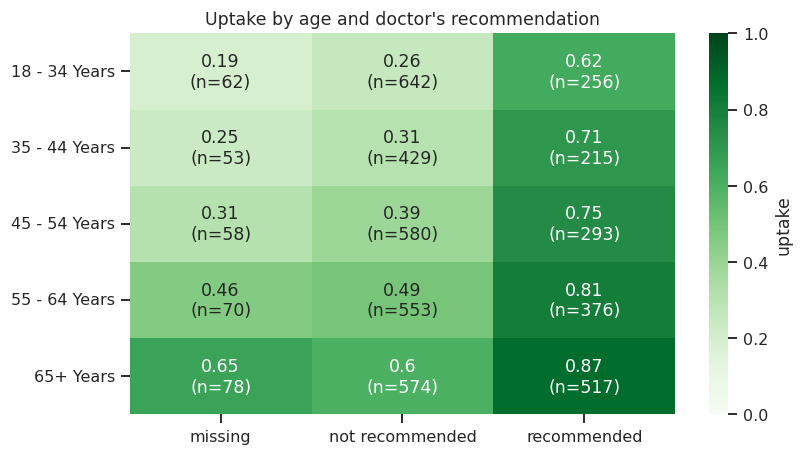

lift from a recommendation, by age: {'18 - 34 Years': 0.366, '35 - 44 Years': 0.399, '45 - 54 Years': 0.358, '55 - 64 Years': 0.312, '65+ Years': 0.273}


In [19]:
doc = df_train["doctor_recc_seasonal"].map({0: "not recommended", 1: "recommended"}).fillna("missing")
rate = df_train.groupby([df_train["age_group"], doc])[TARGET].mean().unstack()
count = df_train.groupby([df_train["age_group"], doc])[TARGET].size().unstack()
labels = rate.round(2).astype(str) + "\n(n=" + count.astype(str) + ")"
plt.figure(figsize=(8, 4.5))
sns.heatmap(rate, annot=labels, fmt="", cmap="Greens", vmin=0, vmax=1, cbar_kws={"label": "uptake"})
plt.title("Uptake by age and doctor's recommendation"); plt.xlabel(""); plt.ylabel(""); plt.show()
lift = (rate["recommended"] - rate["not recommended"]).round(3)
print("lift from a recommendation, by age:", lift.to_dict())

### B.11 Does the test set look like the training set?
Cross-validation only predicts test performance if the two files come from the same population. **Adversarial validation**: a model is trained to tell training rows from test rows. An AUC near 0.5 means it cannot, so the files are alike; an AUC well above 0.5 would mean a shift that CV would not see.

train-vs-test AUC: 0.493 ± 0.002


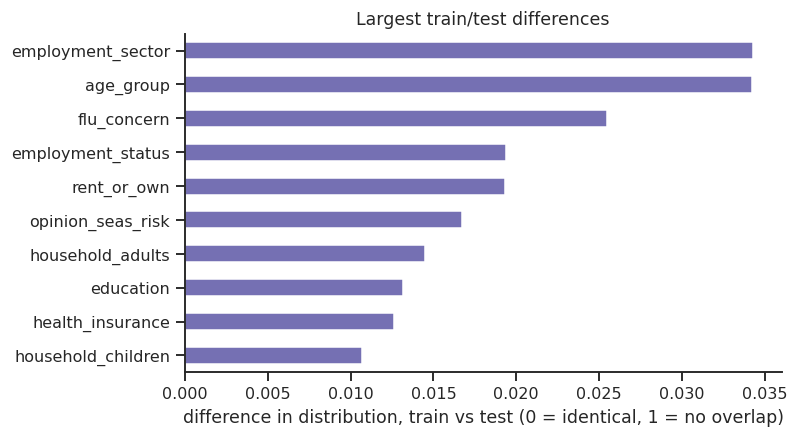

largest difference: employment_sector (0.034)


In [20]:
from sklearn.model_selection import cross_val_score
both = pd.concat([df_train.drop(columns=[KEY, TARGET]), df_test.drop(columns=KEY)], ignore_index=True)
for c in both.select_dtypes("object"):
    both[c] = both[c].astype("category")
is_test = np.r_[np.zeros(len(df_train)), np.ones(len(df_test))]
adv_auc = cross_val_score(LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=RANDOM_STATE),
                          both, is_test, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc")
print(f"train-vs-test AUC: {adv_auc.mean():.3f} ± {adv_auc.std():.3f}")

shift = {}
for c in both.columns:
    a = df_train[c].astype("string").fillna("missing").value_counts(normalize=True)
    b = df_test[c].astype("string").fillna("missing").value_counts(normalize=True)
    shift[c] = 0.5 * a.sub(b, fill_value=0).abs().sum()      # total variation distance, 0 = identical
shift = pd.Series(shift).sort_values(ascending=False)
shift.head(10).sort_values().plot(kind="barh", figsize=(7, 4), color=PALETTE["neutral"])
plt.xlabel("difference in distribution, train vs test (0 = identical, 1 = no overlap)")
plt.title("Largest train/test differences"); plt.show()
print(f"largest difference: {shift.index[0]} ({shift.iloc[0]:.3f})")

### B.12 What the exploration decided
| Finding (cells above) | Decision |
|---|---|
| Uptake is 53.6%, close to 50/50 (B.2) | stratified folds; no resampling or class weights needed |
| All 29 columns fall inside the sheet's ranges; no duplicate ids or rows; no train/test overlap (B.1) | no rows dropped, no capping |
| 98.9% of missing employment sectors belong to people not employed; uptake with insurance missing is 46%, between insured (63%) and uninsured (26%) (B.2) | keep "missing" as its own level or flag, never fill with a guess (tested in C.3) |
| Questions are skipped in blocks (e.g. the three opinion scales, correlation 0.87-0.93; education, marital and employment status, 0.86-0.90), and people with 5+ gaps take the jab less (41% vs 55%) (B.9) | missing-value flags carry information; tree models see NaN directly |
| Perceived risk (V = 0.40), belief the jab works (0.39) and a doctor's recommendation (0.35) are the strongest signals; most behaviours are below 0.10 (B.8) | an engineered `doctor_and_belief` feature, and a `precautions` count added next to the seven weak flags so their combined signal is easier to use |
| The opinion scales put "Don't know" at 3, in the middle (B.4) | test one-hot encoding of the opinion scales against treating them as numbers (C.3) |
| A doctor's recommendation lifts uptake by 27 points for the 65+ but by 31-40 points for younger groups (B.10) | compare linear models with tree models, which can learn interactions |
| The 65+ are 24.6% of residents but carry 73% of the expected hospital bill (B.6) | personal cut-off in the decision rule (A.3) |
| A model cannot tell training rows from test rows (AUC 0.49); the largest single difference is 0.03 (B.11) | no shift: cross-validated bills are a fair guide to the test set |

## Part C. The models
### C.1 Features and two encodings
Two hand-made features: `precautions` (how many of the seven protective behaviours a person reports) and `doctor_and_belief` (doctor recommended it × believes the jab works).

* **Encoding L (linear models and the neural network):** numeric columns get median imputation with a missing-flag and scaling; categoricals are one-hot encoded with "missing" as its own level.
* **Encoding T (tree models):** categoricals are ordinal codes with missing = −1; numeric gaps stay as NaN where the model supports it.

In [21]:
CATEGORICAL = ["age_group", "education", "race", "sex", "income_poverty", "marital_status",
               "rent_or_own", "employment_status", "census_msa", "employment_sector"]
BEHAVIOURS = [c for c in df_train if c.startswith("behavioral_")]


def build_features(frame):
    out = frame.drop(columns=[KEY, TARGET], errors="ignore").copy()
    out["precautions"] = out[BEHAVIOURS].sum(axis=1, min_count=1)
    out["doctor_and_belief"] = out["doctor_recc_seasonal"] * out["opinion_seas_vacc_effective"]
    for c in CATEGORICAL:
        out[c] = out[c].astype("object")
    return out


X = build_features(df_train)
X_test = build_features(df_test)
NUMERIC = [c for c in X if c not in CATEGORICAL]

encode_L = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMERIC),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                          OneHotEncoder(handle_unknown="ignore", min_frequency=20)), CATEGORICAL)])

encode_T = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), CATEGORICAL),
    ("num", "passthrough", NUMERIC)])
encode_T_filled = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), CATEGORICAL),
    ("num", SimpleImputer(strategy="constant", fill_value=-1), NUMERIC)])
IS_CAT = [True] * len(CATEGORICAL) + [False] * len(NUMERIC)
print(f"{X.shape[1]} columns in: {len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical")

31 columns in: 21 numeric, 10 categorical


### C.2 How every model is judged
**10-fold stratified cross-validation, repeated twice (20 folds).** In each fold the model is trained on 90% of the residents and predicts `q` for the other 10%. Those residents are then posted to (or not) with the personal cut-off from A.3, and the fold's town bill is divided by the number of residents.

The result is a mean bill per resident and its spread over 20 folds. Much of that spread comes from which residents land in each fold, so section D.2 also compares models fold by fold. AUC and Brier score are recorded too, but they do not decide anything.

In [22]:
FOLDS = RepeatedStratifiedKFold(n_splits=10, n_repeats=2, random_state=RANDOM_STATE)
results, oof_q = {}, {}


def score_model(name, estimator, store=True):
    # store=False is used for pre-processing experiments, which should not enter the submission league table
    per_fold, q_sum, q_n = [], np.zeros(N), np.zeros(N)
    for train_idx, valid_idx in FOLDS.split(X, y):
        fitted = clone(estimator).fit(X.iloc[train_idx], y[train_idx])
        q = fitted.predict_proba(X.iloc[valid_idx])[:, 1]
        ru, rv, yv = r_u_train[valid_idx], r_v_train[valid_idx], y[valid_idx]
        per_fold.append({
            "bill": town_bill(yv, post_vaccine(q, ru, rv), ru, rv) / len(valid_idx),
            "bill_at_half": town_bill(yv, q >= 0.5, ru, rv) / len(valid_idx),
            "auc": roc_auc_score(yv, q), "brier": brier_score_loss(yv, q)})
        q_sum[valid_idx] += q; q_n[valid_idx] += 1
    r = pd.DataFrame(per_fold)
    if store:
        results[name], oof_q[name] = r, q_sum / q_n
    print(f"{name:<26} ${r.bill.mean():7.2f} ± {r.bill.std():5.2f} per resident   AUC {r.auc.mean():.3f}   Brier {r.brier.mean():.4f}")
    return r


candidates = {
    "Logistic (L2)": make_pipeline(encode_L, LogisticRegression(C=0.2, max_iter=5000)),
    "Neural net (MLP)": make_pipeline(encode_L, MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-2, learning_rate_init=1e-3,
                                       early_stopping=True, max_iter=500, random_state=RANDOM_STATE)),
    "Extra trees": make_pipeline(encode_T_filled, ExtraTreesClassifier(n_estimators=500, min_samples_leaf=8, max_features=0.4,
                                  n_jobs=-1, random_state=RANDOM_STATE)),
    "LightGBM": make_pipeline(encode_T, LGBMClassifier(n_estimators=350, learning_rate=0.03, num_leaves=12, min_child_samples=40,
                               subsample=0.85, subsample_freq=1, colsample_bytree=0.7, reg_lambda=2.0,
                               random_state=RANDOM_STATE, verbose=-1)),
}
for name, est in candidates.items():
    _ = score_model(name, est)

Logistic (L2)              $ 330.25 ± 11.34 per resident   AUC 0.849   Brier 0.1572
Neural net (MLP)           $ 330.33 ± 10.89 per resident   AUC 0.841   Brier 0.1619
Extra trees                $ 329.62 ± 11.31 per resident   AUC 0.845   Brier 0.1601
LightGBM                   $ 329.68 ± 11.14 per resident   AUC 0.852   Brier 0.1553


### C.3 Comparing pre-processing options
To see which pre-processing choices matter, each option is scored on the **same model and the same 20 folds**, so the only thing that changes is the pre-processing. Because the folds are shared, the per-fold difference from the baseline is a fair, paired comparison.

Logistic regression (sensitive to encoding):
* **L-base:** encoding L as above (median + missing-flags + scaling, one-hot categoricals);
* **L-no-flags:** most-frequent imputation everywhere, no missing-value flags (missingness thrown away);
* **L-opinions-binned:** the three opinion scales are one-hot encoded as categories, so "Don't know" (3) is no longer treated as halfway between "low" and "high";
* **L-no-engineered:** the two hand-made features are left out.

LightGBM (tree model):
* **T-native-NaN:** gaps left as NaN for LightGBM to route itself (as in C.2);
* **T-filled:** gaps replaced by −1 before training.

In [23]:
OPINIONS = ["opinion_seas_vacc_effective", "opinion_seas_risk", "opinion_seas_sick_from_vacc"]
ENGINEERED = ["precautions", "doctor_and_belief"]


def encoder_L(numeric, categorical, flags=True, num_strategy="median"):
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy=num_strategy, add_indicator=flags), StandardScaler()), numeric),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing") if flags else SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", min_frequency=20)), categorical)])


logit = LogisticRegression(C=0.2, max_iter=5000)
lgbm = candidates["LightGBM"].steps[-1][1]
prep_options = {
    "L-base": make_pipeline(encoder_L(NUMERIC, CATEGORICAL), logit),
    "L-no-flags": make_pipeline(encoder_L(NUMERIC, CATEGORICAL, flags=False, num_strategy="most_frequent"), logit),
    # opinions as categories: missing answers become level 0, then every level (0-5) gets its own indicator column
    "L-opinions-binned": make_pipeline(ColumnTransformer(
        encoder_L([c for c in NUMERIC if c not in OPINIONS], CATEGORICAL).transformers
        + [("opinion", make_pipeline(SimpleImputer(strategy="constant", fill_value=0),
                                     OneHotEncoder(handle_unknown="ignore")), OPINIONS)]), logit),
    "L-no-engineered": make_pipeline(encoder_L([c for c in NUMERIC if c not in ENGINEERED], CATEGORICAL), logit),
    "T-native-NaN": make_pipeline(encode_T, lgbm),
    "T-filled": make_pipeline(encode_T_filled, lgbm),
}
prep_runs = {name: score_model(name, est, store=False) for name, est in prep_options.items()}

baseline_of = {n: ("L-base" if n.startswith("L") else "T-native-NaN") for n in prep_runs}
prep_table = pd.DataFrame({
    n: {"$ per resident": r.bill.mean(), "paired diff vs baseline": (r.bill - prep_runs[baseline_of[n]].bill).mean(),
        "sd of paired diff": (r.bill - prep_runs[baseline_of[n]].bill).std(),
        "folds cheaper than baseline": int(((r.bill - prep_runs[baseline_of[n]].bill) < 0).sum()),
        "AUC": r.auc.mean(), "Brier": r.brier.mean()} for n, r in prep_runs.items()}).T
for n, r in prep_table.drop(index=["L-base", "T-native-NaN"]).iterrows():
    verdict = "helps" if r["folds cheaper than baseline"] >= 15 else ("hurts" if r["folds cheaper than baseline"] <= 5 else "makes no clear difference")
    print(f"{n:<18} {verdict:<26} (cheaper in {int(r['folds cheaper than baseline'])}/20 folds, mean {r['paired diff vs baseline']:+.2f} $)")
prep_table.style.format({"AUC": "{:.3f}", "Brier": "{:.4f}", "folds cheaper than baseline": "{:.0f}"}, precision=2)

L-base                     $ 330.25 ± 11.34 per resident   AUC 0.849   Brier 0.1572
L-no-flags                 $ 329.74 ± 11.73 per resident   AUC 0.846   Brier 0.1585
L-opinions-binned          $ 329.33 ± 11.16 per resident   AUC 0.852   Brier 0.1555
L-no-engineered            $ 330.19 ± 11.35 per resident   AUC 0.849   Brier 0.1571
T-native-NaN               $ 329.68 ± 11.14 per resident   AUC 0.852   Brier 0.1553
T-filled                   $ 329.53 ± 11.14 per resident   AUC 0.852   Brier 0.1554
L-no-flags         makes no clear difference  (cheaper in 10/20 folds, mean -0.51 $)
L-opinions-binned  helps                      (cheaper in 16/20 folds, mean -0.93 $)
L-no-engineered    makes no clear difference  (cheaper in 7/20 folds, mean -0.06 $)
T-filled           makes no clear difference  (cheaper in 13/20 folds, mean -0.16 $)


,$ per resident,paired diff vs baseline,sd of paired diff,folds cheaper than baseline,AUC,Brier
L-base,330.25,0.00,0.00,0,0.849,0.1572
L-no-flags,329.74,-0.51,1.50,10,0.846,0.1585
L-opinions-binned,329.33,-0.93,1.17,16,0.852,0.1555
L-no-engineered,330.19,-0.06,0.28,7,0.849,0.1571
T-native-NaN,329.68,0.00,0.00,0,0.852,0.1553
T-filled,329.53,-0.16,0.92,13,0.852,0.1554


A negative paired difference means the option is cheaper than its baseline. "Folds cheaper" counts how many of the 20 folds the option beat the baseline in; 10 of 20 is what pure chance would give.

### C.4 Tuning hyper-parameters
Three model families are tuned by search. The searches optimise **log loss**: the cut-off rule only works if `q` is a trustworthy probability, and log loss rewards exactly that. Each tuned model is then judged on the town bill like every other model.

* logistic regression: strength of regularisation `C` (grid search);
* LightGBM and `HistGradientBoostingClassifier` (with native categorical splits): randomised search over tree size, learning rate and regularisation.

The searches use the same training data that the cross-validation later scores, so the tuned models' CV bills are slightly optimistic (see the critical review).

In [24]:
from sklearn.model_selection import GridSearchCV
TUNE_CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

logit_search = GridSearchCV(candidates["Logistic (L2)"], {"logisticregression__C": [0.01, 0.03, 0.1, 0.2, 0.5, 1, 3]},
                            scoring="neg_log_loss", cv=TUNE_CV, n_jobs=-1).fit(X, y)
print("logistic: best C =", logit_search.best_params_["logisticregression__C"], f"| log loss {-logit_search.best_score_:.4f}")
candidates["Logistic (tuned)"] = logit_search.best_estimator_
_ = score_model("Logistic (tuned)", candidates["Logistic (tuned)"])

lgbm_search = RandomizedSearchCV(
    candidates["LightGBM"],
    {"lgbmclassifier__n_estimators": [200, 350, 500, 800], "lgbmclassifier__learning_rate": [0.01, 0.02, 0.03, 0.05],
     "lgbmclassifier__num_leaves": [6, 12, 24], "lgbmclassifier__min_child_samples": [20, 40, 80],
     "lgbmclassifier__colsample_bytree": [0.5, 0.7, 0.9], "lgbmclassifier__reg_lambda": [0, 2, 10]},
    n_iter=20, scoring="neg_log_loss", cv=TUNE_CV, random_state=RANDOM_STATE, n_jobs=-1).fit(X, y)
print("LightGBM:", {k.split("__")[1]: v for k, v in lgbm_search.best_params_.items()}, f"| log loss {-lgbm_search.best_score_:.4f}")
candidates["LightGBM (tuned)"] = lgbm_search.best_estimator_
_ = score_model("LightGBM (tuned)", candidates["LightGBM (tuned)"])

logistic: best C = 0.1 | log loss 0.4894
Logistic (tuned)           $ 330.10 ± 11.32 per resident   AUC 0.848   Brier 0.1574
LightGBM: {'reg_lambda': 10, 'num_leaves': 12, 'n_estimators': 350, 'min_child_samples': 80, 'learning_rate': 0.03, 'colsample_bytree': 0.5} | log loss 0.4796
LightGBM (tuned)           $ 329.14 ± 11.28 per resident   AUC 0.853   Brier 0.1549


In [25]:
hgb = make_pipeline(encode_T, HistGradientBoostingClassifier(categorical_features=IS_CAT, random_state=RANDOM_STATE))
search = RandomizedSearchCV(
    hgb,
    {"histgradientboostingclassifier__learning_rate": [0.02, 0.04, 0.06, 0.1],
     "histgradientboostingclassifier__max_iter": [150, 250, 400],
     "histgradientboostingclassifier__max_leaf_nodes": [8, 15, 31],
     "histgradientboostingclassifier__min_samples_leaf": [20, 40, 80],
     "histgradientboostingclassifier__l2_regularization": [0.0, 1.0, 5.0]},
    n_iter=20, scoring="neg_log_loss", cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1).fit(X, y)
print("chosen settings:", {k.split("__")[1]: v for k, v in search.best_params_.items()})
print(f"5-fold log loss {-search.best_score_:.4f}")
candidates["Gradient boosting (tuned)"] = search.best_estimator_
_ = score_model("Gradient boosting (tuned)", candidates["Gradient boosting (tuned)"])

chosen settings: {'min_samples_leaf': 20, 'max_leaf_nodes': 8, 'max_iter': 400, 'learning_rate': 0.02, 'l2_regularization': 5.0}
5-fold log loss 0.4797
Gradient boosting (tuned)  $ 329.19 ± 11.32 per resident   AUC 0.854   Brier 0.1545


### C.5 Calibrating the extra trees
Random-forest-style models tend to push probabilities towards the middle. Sigmoid (Platt) calibration is tried on the extra trees to see whether a better-shaped `q` lowers the bill.

Extra trees (calibrated)   $ 329.24 ± 11.66 per resident   AUC 0.846   Brier 0.1588


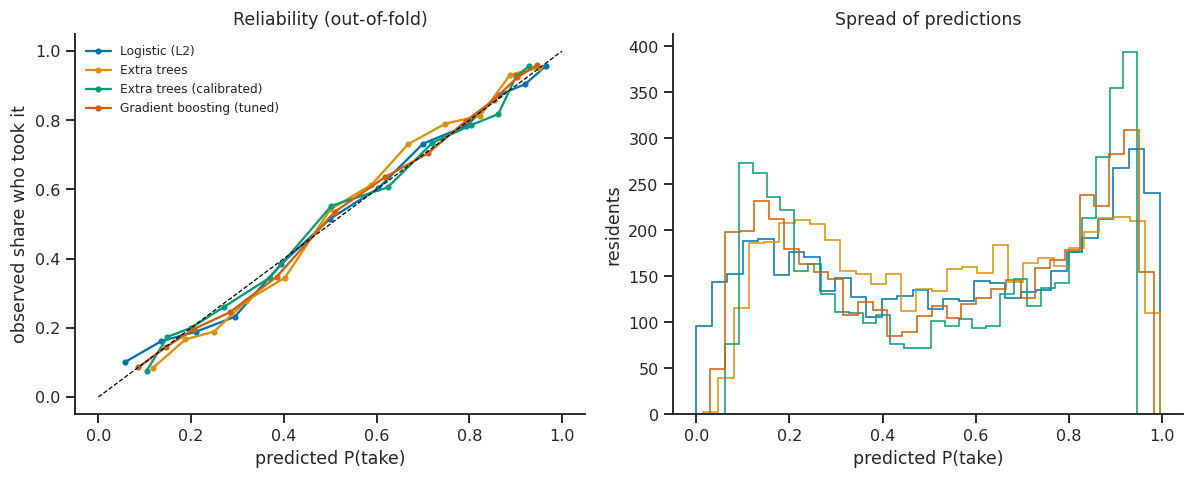

In [26]:
candidates["Extra trees (calibrated)"] = CalibratedClassifierCV(candidates["Extra trees"], method="sigmoid", cv=4)
_ = score_model("Extra trees (calibrated)", candidates["Extra trees (calibrated)"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name in ["Logistic (L2)", "Extra trees", "Extra trees (calibrated)", "Gradient boosting (tuned)"]:
    obs, pred = calibration_curve(y, oof_q[name], n_bins=12, strategy="quantile")
    axes[0].plot(pred, obs, marker=".", label=name)
    axes[1].hist(oof_q[name], bins=30, histtype="step", lw=1.5, label=name)
axes[0].plot([0, 1], [0, 1], color="black", lw=0.8, ls="--")
axes[0].set(xlabel="predicted P(take)", ylabel="observed share who took it", title="Reliability (out-of-fold)")
axes[1].set(xlabel="predicted P(take)", ylabel="residents", title="Spread of predictions")
axes[0].legend(fontsize=8, frameon=False); plt.tight_layout(); plt.show()

### C.6 Stacking
A stacked model lets a small logistic regression learn how much to trust each of three different learners (linear, bagged trees, boosted trees). The blend weights are learnt on inner folds, so they are never fitted on the rows they are scored on.

In [ ]:
candidates["Stacked"] = StackingClassifier(
    estimators=[("lin", candidates["Logistic (tuned)"]), ("et", candidates["Extra trees"]),
                ("gb", candidates["Gradient boosting (tuned)"])],
    final_estimator=LogisticRegression(max_iter=2000), stack_method="predict_proba",
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
_ = score_model("Stacked", candidates["Stacked"])

## Part D. The decision
### D.1 League table

In [ ]:
league = pd.DataFrame({
    name: {"$ per resident": r.bill.mean(), "spread (sd)": r.bill.std(), "$ at 0.5 cut-off": r.bill_at_half.mean(),
           "AUC": r.auc.mean(), "Brier": r.brier.mean()} for name, r in results.items()}).T.sort_values("$ per resident")
league["saved vs post to nobody"] = reference.loc["post to nobody", "$ per resident"] - league["$ per resident"]
order = league.index.tolist()
league.style.format({"AUC": "{:.3f}", "Brier": "{:.4f}"}, precision=2).background_gradient(subset=["$ per resident"], cmap="Greens_r")

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, name in enumerate(order[::-1]):
    bills = results[name].bill
    ax.scatter(bills, np.full(len(bills), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(bills)),
               s=10, alpha=0.35, color=PALETTE["neutral"])
    ax.errorbar(bills.mean(), i, xerr=bills.std(), fmt="D", color="black", ms=5, capsize=3)
ax.set_yticks(range(len(order)), order[::-1])
for label, colour in [("post to nobody", PALETTE["refuse"]), ("oracle (knows who takes it)", PALETTE["take"])]:
    ax.axvline(reference.loc[label, "$ per resident"], color=colour, ls="--", lw=1, label=label)
ax.set(xlabel="town bill per resident ($), each dot = one of 20 folds", title="Lower is better")
ax.legend(frameon=False, fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

### D.2 Are the differences real? A paired comparison
The spread above is large because some folds simply contain more older, high-risk residents than others, and that moves **every** model's bill together. Since every model was scored on exactly the same 20 folds, a fairer test is the **per-fold difference** from the leader: if a model is truly worse, it should be worse in most folds, not just on average.

In [ ]:
leader = order[0]
paired = pd.DataFrame({
    name: {"mean extra $ vs leader": (results[name].bill - results[leader].bill).mean(),
           "sd of the difference": (results[name].bill - results[leader].bill).std(),
           "folds where leader is cheaper": int((results[name].bill > results[leader].bill).sum())}
    for name in order[1:]}).T
paired["t (mean / standard error)"] = paired["mean extra $ vs leader"] / (paired["sd of the difference"] / np.sqrt(len(results[leader])))
display(paired.style.format({"folds where leader is cheaper": "{:.0f}"}, precision=2))

diffs = pd.DataFrame({n: results[n].bill - results[leader].bill for n in order[1:]})
ax = sns.stripplot(data=diffs, orient="h", color=PALETTE["neutral"], alpha=0.6, size=4)
sns.pointplot(data=diffs, orient="h", color="black", errorbar=("ci", 95), linestyle="none", markers="D", ax=ax)
ax.axvline(0, color=PALETTE["take"], lw=1)
ax.set(xlabel=f"extra $ per resident compared with {leader} (same fold)", title="Paired differences, 20 folds (diamond = mean, 95% CI)")
plt.show()

Folds are not fully independent (the two repeats reuse the same residents), so the t-values are a rough guide, not a formal test. A model that the leader beats in, say, 15 or more of the 20 folds is reliably worse; a model near 10 of 20 is effectively tied with it.

### D.3 Confusion matrix, in counts and in dollars
The rubric asks for standard performance measures as well as the task metric. The out-of-fold probabilities of the leading model are turned into decisions with the personal cut-off and with 0.5, and compared with what residents actually did.

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
q_lead = oof_q[leader]
decisions = {"personal cut-off": post_vaccine(q_lead, r_u_train, r_v_train), "0.5 cut-off": q_lead >= 0.5}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
summary_rows = []
for ax, (rule, posted) in zip(axes, decisions.items()):
    cm = confusion_matrix(y, posted, labels=[0, 1])
    cell_cost = np.zeros((2, 2))
    for t in (0, 1):
        for p in (0, 1):
            m = (y == t) & (posted == p)
            cell_cost[t, p] = town_bill(y[m], posted[m], r_u_train[m], r_v_train[m])
    labels = np.array([[f"{cm[t, p]:,}\n${cell_cost[t, p] / 1e3:,.0f}k" for p in (0, 1)] for t in (0, 1)])
    sns.heatmap(cm, annot=labels, fmt="", cmap="Purples", cbar=False, ax=ax,
                xticklabels=["not posted", "posted"], yticklabels=["refused", "took it"])
    ax.set(title=f"{rule}: town bill ${cell_cost.sum() / 1e6:,.3f}m", xlabel="our decision", ylabel="what the resident did")
    summary_rows.append({"rule": rule, "accuracy": accuracy_score(y, posted), "precision": precision_score(y, posted),
                         "recall": recall_score(y, posted), "share posted": posted.mean(), "$ per resident": cell_cost.sum() / N})
plt.suptitle(f"{leader}, out-of-fold (each cell: residents and their total cost)", y=1.03); plt.tight_layout(); plt.show()
pd.DataFrame(summary_rows).set_index("rule").round(3)

The next cell prints how much one accepted dose saves in expected hospital cost for different residents, against the $300 it costs. Where the saving is far below $300, a dose is only worth posting when the resident is both very likely to use it and at real risk, which is why the personal cut-off can post far fewer doses than the 0.5 rule. Accuracy can go down while the bill goes down too, which is the clearest evidence that accuracy is the wrong yardstick for this task.

In [ ]:
eg = pd.DataFrame({"age_group": ["18 - 34 Years", "45 - 54 Years", "65+ Years", "65+ Years", "65+ Years"],
                   "number_chronic_med_conditions": [0, 0, 0, 1, 2]})
ru_eg, rv_eg = resident_risk(eg)
eg["saving per accepted dose $"] = ((ru_eg - rv_eg) * COST_HOSPITAL).round(0)
eg["personal cut-off"] = cutoff(ru_eg, rv_eg).round(2)
eg

### D.4 Who gets a vaccine?

In [ ]:
posted_lead = decisions["personal cut-off"]
who = pd.DataFrame({"age_group": df_train["age_group"], "chronic": df_train["number_chronic_med_conditions"].clip(upper=2),
                    "posted": posted_lead, "took it": y})
by_age = who.groupby("age_group").agg(residents=("posted", "size"), share_posted=("posted", "mean"), uptake=("took it", "mean"))
by_age["mean personal cut-off"] = pd.Series(cutoff(r_u_train, r_v_train)).groupby(df_train["age_group"].to_numpy()).mean()
display(by_age.round(3))
sns.heatmap(who.pivot_table(index="age_group", columns="chronic", values="posted", aggfunc="mean"),
            annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, cbar_kws={"label": "share posted"})
plt.title(f"Share of residents posted a vaccine ({leader}, out-of-fold)"); plt.xlabel("chronic conditions (2 = 2 or more)"); plt.show()

### D.5 How much does the cut-off matter?
The same out-of-fold probabilities, turned into decisions three ways:
1. the usual **0.5** cut-off;
2. the **single best cut-off** for everybody, searched on the same out-of-fold predictions (this flatters it, because the cut-off is chosen on the data it is scored on);
3. the **personal cut-off** from A.3, which needs no searching at all.

In [ ]:
grid_t = np.linspace(0.05, 0.95, 91)
rows = []
for name in order:
    q = oof_q[name]
    flat = [town_bill(y, q >= t, r_u_train, r_v_train) / N for t in grid_t]
    rows.append({"model": name, "0.5 cut-off": town_bill(y, q >= 0.5, r_u_train, r_v_train) / N,
                 "best single cut-off": min(flat), "chosen single cut-off": grid_t[int(np.argmin(flat))],
                 "personal cut-off": town_bill(y, post_vaccine(q, r_u_train, r_v_train), r_u_train, r_v_train) / N})
rules = pd.DataFrame(rows).set_index("model")
display(rules.style.format(precision=2))

ax = rules[["0.5 cut-off", "best single cut-off", "personal cut-off"]].plot(
    kind="barh", figsize=(8.5, 5.5), color=[PALETTE["grey"], PALETTE["neutral"], PALETTE["take"]], width=0.8)
ax.set_xlim(rules.drop(columns="chosen single cut-off").to_numpy().min() * 0.98)
ax.invert_yaxis(); ax.set_xlabel("$ per resident"); ax.set_title("Same probabilities, three decision rules")
ax.legend(frameon=False, fontsize=8); plt.show()

print(f"{leader}: personal cut-offs save ${(rules.loc[leader, '0.5 cut-off'] - rules.loc[leader, 'personal cut-off']) * len(df_test):,.0f} "
      f"over the 0.5 rule for a town of {len(df_test):,} residents.")

## Part E. Robustness
The hospitalisation risks and the vaccine's effect come from AI estimates, so they could be wrong. Each model's out-of-fold probabilities are re-scored with the risks multiplied by 0.4 (about the lowest AI answer) up to 2, and with the vaccine preventing 20%, 40% or 60% of hospitalisations (18 scenarios). If the order of the models hardly moves, the submission ranking does not hinge on the guesses.

In [ ]:
records = []
for scale in [0.4, 0.5, 0.75, 1.0, 1.5, 2.0]:
    for effect in [0.2, 0.4, 0.6]:
        ru, rv = resident_risk(df_train, table=(RISK_TABLE * scale).clip(upper=1), effect=effect)
        for name in order:
            records.append({"risk scale": scale, "vaccine effect": effect, "model": name,
                            "bill": town_bill(y, post_vaccine(oof_q[name], ru, rv), ru, rv) / N})
sens = pd.DataFrame(records)
sens["rank"] = sens.groupby(["risk scale", "vaccine effect"])["bill"].rank(method="min").astype(int)

g = sns.relplot(data=sens, x="risk scale", y="rank", hue="model", col="vaccine effect", kind="line", marker="o",
                height=3.6, aspect=0.9, hue_order=order)
for ax in g.axes.flat:
    ax.invert_yaxis(); ax.set_yticks(range(1, len(order) + 1))
g.fig.suptitle("Model rank under different hospitalisation assumptions (1 = cheapest)", y=1.04); plt.show()

stability = sens.groupby("model")["rank"].agg(["mean", "min", "max"]).loc[order]
stability["ranked 1st (of 18 scenarios)"] = sens[sens["rank"] == 1]["model"].value_counts().reindex(order).fillna(0).astype(int)
most_robust = stability["mean"].idxmin()
print(f"best average rank across the 18 scenarios: {most_robust} (mean rank {stability.loc[most_robust, 'mean']:.2f}); "
      f"best at the A.4 values: {order[0]} (mean rank {stability.loc[order[0], 'mean']:.2f})")
stability

## Part F. Delivery
### F.1 The five submission files
The brief asks for five results that are **all different**, ordered best to worst by the task metric. Models are taken in league-table order (cheapest cross-validated bill first). A model is skipped if its out-of-fold decisions agree with an already chosen model for more than 99% of residents, because it would effectively be the same submission twice.

**Tie-break.** The lecturers will score our files with their own hospitalisation figures, not ours. So when two neighbouring models are tied within the noise (the cheaper one wins fewer than 15 of the 20 paired folds), the one with the better average rank across the 18 scenarios in Part E goes first. A clear win at our best estimate always keeps its place.

Each chosen model is refitted on all 4,756 training residents. Its test probabilities go through the personal cut-off, and the result is saved as `challenge_submission_group_<GROUP_ID>_order_<k>.csv`, where order 1 is the lowest expected bill. The `seasonal_vaccine` column holds **our decision** (1.0 = post a vaccine, 0.0 = do not), in the same format as the example file. Every file is checked against the example before it is written.

In [ ]:
chosen = []
for name in order:
    dec = post_vaccine(oof_q[name], r_u_train, r_v_train)
    clash = [c for c in chosen if (post_vaccine(oof_q[c], r_u_train, r_v_train) == dec).mean() > 0.99]
    if clash:
        print(f"skipped {name}: decisions match {clash[0]} for more than 99% of residents")
        continue
    chosen.append(name)
    if len(chosen) == 5:
        break
print("league order of the five:", chosen)

# tie-break: within-noise neighbours are ordered by robustness (mean rank across the Part E scenarios)
for _ in range(len(chosen)):
    for i in range(len(chosen) - 1):
        first, second = chosen[i], chosen[i + 1]
        first_wins = int((results[second].bill > results[first].bill).sum())
        if first_wins < 15 and stability.loc[second, "mean"] < stability.loc[first, "mean"]:
            chosen[i], chosen[i + 1] = second, first
            print(f"swapped: {second} (mean scenario rank {stability.loc[second, 'mean']:.2f}) before {first} "
                  f"({stability.loc[first, 'mean']:.2f}); {first} was cheaper in only {first_wins}/20 folds")
print("submission order:", chosen)

manifest = []
for k, name in enumerate(chosen, start=1):
    model = clone(candidates[name]).fit(X, y)
    q_test = model.predict_proba(X_test)[:, 1]
    posted = post_vaccine(q_test, r_u_test, r_v_test)
    out = pd.DataFrame({KEY: df_test[KEY].to_numpy(), TARGET: posted.astype(df_example[TARGET].dtype)})

    assert list(out.columns) == list(df_example.columns), "column names differ from the example"
    assert out[KEY].equals(df_example[KEY]), "ids or their order differ from the example"
    assert out[TARGET].isin([0, 1]).all() and out[TARGET].notna().all()

    path = f"challenge_submission_group_{GROUP_ID}_order_{k}.csv"
    out.to_csv(path, index=False)
    manifest.append({"order": k, "file": path, "model": name,
                     "CV $ per resident": round(league.loc[name, "$ per resident"], 2),
                     "CV sd": round(league.loc[name, "spread (sd)"], 2),
                     "paired extra $ vs order 1": 0.0 if k == 1 else round((results[name].bill - results[chosen[0]].bill).mean(), 2),
                     "doses posted": int(posted.sum()), "share posted": round(posted.mean(), 3),
                     "model's own expected test bill $": round(float((COST_VACCINE * np.maximum(posted, q_test)
                                                    + COST_HOSPITAL * np.where(posted, q_test * r_v_test + (1 - q_test) * r_u_test, r_u_test)).sum()))})

manifest = pd.DataFrame(manifest)
manifest.to_csv("ranking.csv", index=False)
assert len(manifest) == 5 and manifest["file"].nunique() == 5
manifest

`model's own expected test bill` uses each model's own probabilities, so it is that model's estimate of its own bill, not a score. The ranking uses only the cross-validated bill.

In [ ]:
# The five files must not be identical; show how often each pair agrees
subs = {r.order: pd.read_csv(r.file)[TARGET].to_numpy() for r in manifest.itertuples()}
agree = pd.DataFrame({a: {b: (subs[a] == subs[b]).mean() for b in subs} for a in subs})
assert all(agree.loc[a, b] < 1 for a in subs for b in subs if a != b), "two submission files are identical"
sns.heatmap(agree, annot=True, fmt=".3f", cmap="Greens", vmin=0.8, vmax=1, cbar=False)
plt.title("Share of test residents with the same decision (order 1-5)"); plt.show()

### F.2 Explainability (first version, to be extended after the hackathon)
Four techniques, from model-agnostic to model-specific:
1. **Permutation importance in dollars, for every model:** how much the town bill rises when one column is shuffled. This is the only importance measure here that speaks the task's language (money), and it allows models to be compared side by side.
2. **SHAP values** for the best tree model: which way, and how strongly, each feature pushes an individual's predicted chance of taking the jab.
3. **Coefficients** of the tuned logistic regression: a transparent check on the direction of each effect.
4. **Partial dependence** for the strongest survey answers: how the predicted uptake changes as one answer changes, averaged over everyone.

All four are computed on one held-out fifth of the training data (models trained on the other four fifths).

In [ ]:
inner = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
tr_idx, va_idx = next(inner.split(X, y))
X_tr, X_va, y_tr, y_va = X.iloc[tr_idx], X.iloc[va_idx], y[tr_idx], y[va_idx]
ru_va, rv_va = r_u_train[va_idx], r_v_train[va_idx]


def bill_scorer(est, Xv, yv):
    # negative town bill per resident, so that "higher is better" as sklearn expects
    q = est.predict_proba(Xv)[:, 1]
    return -town_bill(yv, post_vaccine(q, ru_va, rv_va), ru_va, rv_va) / len(yv)


fitted_va, perm = {}, {}
for name in order:
    fitted_va[name] = clone(candidates[name]).fit(X_tr, y_tr)
    pi = permutation_importance(fitted_va[name], X_va, y_va, scoring=bill_scorer, n_repeats=5,
                                random_state=RANDOM_STATE, n_jobs=-1)
    perm[name] = pd.Series(pi.importances_mean, index=X.columns)
perm = pd.DataFrame(perm)
top_cols = perm.mean(axis=1).sort_values(ascending=False).index[:14]

plt.figure(figsize=(12, 6))
sns.heatmap(perm.loc[top_cols, order], annot=True, fmt=".1f", cmap="rocket_r", cbar_kws={"label": "extra $ per resident"})
plt.title("Permutation importance in dollars: what each model's bill depends on"); plt.xticks(rotation=30, ha="right"); plt.show()

rank_corr = perm.rank(ascending=False).corr(method="spearman")
print("agreement between models on feature order (Spearman, mean of pairs):",
      round(rank_corr.where(~np.eye(len(rank_corr), dtype=bool)).stack().mean(), 2))
print("top 5 by average:", list(top_cols[:5]))

In [ ]:
import shap
shap_name = next(n for n in order if n in ("Gradient boosting (tuned)", "LightGBM (tuned)", "LightGBM"))
shap_model = fitted_va[shap_name]
X_va_enc = pd.DataFrame(shap_model.steps[0][1].transform(X_va), columns=CATEGORICAL + NUMERIC)
shap_values = shap.TreeExplainer(shap_model.steps[-1][1]).shap_values(X_va_enc)
shap_values = shap_values[1] if isinstance(shap_values, list) else shap_values
shap.summary_plot(shap_values, X_va_enc, max_display=12, show=False)
plt.title(f"SHAP values: {shap_name} (log-odds of taking the jab)"); plt.tight_layout(); plt.show()

shap_rank = pd.Series(np.abs(shap_values).mean(axis=0), index=X_va_enc.columns).sort_values(ascending=False)
print("SHAP top 5:", list(shap_rank.index[:5]), "| permutation top 5 for the same model:",
      list(perm[shap_name].sort_values(ascending=False).index[:5]))

In [ ]:
lr = fitted_va["Logistic (tuned)"]
names = lr.steps[0][1].get_feature_names_out()
coef = pd.Series(lr.steps[-1][1].coef_[0], index=names)
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
show = coef.reindex(coef.abs().sort_values(ascending=False).index[:16]).sort_values()
show.plot(kind="barh", figsize=(7.5, 5.5), color=np.where(show > 0, PALETTE["take"], PALETTE["refuse"]))
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("coefficient (log-odds per standard deviation, or vs the reference level)")
plt.title("Tuned logistic regression: largest effects"); plt.show()

In [ ]:
from sklearn.inspection import PartialDependenceDisplay
pd_feats = ["opinion_seas_risk", "opinion_seas_vacc_effective", "doctor_recc_seasonal", "opinion_seas_sick_from_vacc"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for name, colour in [(shap_name, PALETTE["neutral"]), ("Logistic (tuned)", PALETTE["take"])]:
    # rows with these answers missing are left out, since older scikit-learn versions reject NaN on the grid
    PartialDependenceDisplay.from_estimator(fitted_va[name], X_va.dropna(subset=pd_feats), pd_feats, ax=axes, kind="average",
                                            line_kw={"color": colour, "label": name})
for ax in np.ravel(axes):
    ax.set_ylim(0, 1)
plt.suptitle("Partial dependence: predicted P(take) as one answer changes", y=1.05); plt.legend(frameon=False, fontsize=8); plt.show()

**Reading the XAI critically (check against the outputs above and rewrite in the team's words):**
* Compare the permutation heatmap across models: if every model relies on the same few survey answers, the result is a property of the data, not of one algorithm.
* Permutation importance (dollars) and SHAP (probability) answer different questions. A feature can shift `q` a lot (high SHAP) yet barely change the bill if it mostly moves low-risk residents who are below their cut-off either way.
* `age_group` and `number_chronic_med_conditions` also enter the bill through the cut-off, which permutation does not shuffle; their dollar importance here only reflects their role in predicting uptake.
* Permutation importance understates features that are correlated with others (for example the opinion scales), because the model can lean on the partner when one is shuffled.
* Partial dependence averages over everyone and hides interactions; SHAP's spread of dots shows where the effect differs between residents.

### F.3 Critical review

In [ ]:
best = league.loc[chosen[0]]
d12 = results[chosen[1]].bill - results[chosen[0]].bill
lines = [
    f"Order 1: {chosen[0]} at ${best['$ per resident']:.2f} per resident (fold sd {best['spread (sd)']:.2f}); "
    f"mean rank {stability.loc[chosen[0], 'mean']:.2f} across the Part E scenarios.",
    f"Order 2: {chosen[1]}, {d12.mean():+.2f} $ per resident against order 1 at our estimate; order 1 was cheaper in "
    f"{int((d12 > 0).sum())} of 20 paired folds; mean scenario rank {stability.loc[chosen[1], 'mean']:.2f}.",
    f"Against posting to nobody the town saves ${best['saved vs post to nobody']:.2f} per resident; "
    f"a perfect predictor would save ${reference.loc['post to nobody', '$ per resident'] - reference.loc['oracle (knows who takes it)', '$ per resident']:.2f}.",
    f"Personal cut-offs beat the 0.5 rule by ${rules.loc[chosen[0], '0.5 cut-off'] - rules.loc[chosen[0], 'personal cut-off']:.2f} per resident for this model.",
    f"It ranks first in {int(stability.loc[chosen[0], 'ranked 1st (of 18 scenarios)'])} of 18 hospitalisation scenarios "
    f"(worst rank {int(stability.loc[chosen[0], 'max'])}); the most robust model across scenarios is {stability['mean'].idxmin()}.",
    f"Simply posting to every 65+ resident already captures "
    f"{(reference.loc['post to nobody', '$ per resident'] - reference.loc['post to the 65+ only', '$ per resident']) / (reference.loc['post to nobody', '$ per resident'] - reference.loc['oracle (knows who takes it)', '$ per resident']):.0%}"
    f" of the largest possible saving; the model captures {best['saved vs post to nobody'] / (reference.loc['post to nobody', '$ per resident'] - reference.loc['oracle (knows who takes it)', '$ per resident']):.0%}.",
]
print("\n".join("- " + s for s in lines if s))